In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from patsy import dmatrix
import json

DATA = Path.home() / "workspace" / "agemr-data"
FINAL = DATA / "final_cohort_v1"

B1 = FINAL / "B1_age_varying"
B1.mkdir(exist_ok=True)

bmi = pd.read_csv(
    FINAL / "bmi_primary_earliest.tsv",
    sep="\t",
    dtype={"IID": str}
)

bp = pd.read_csv(
    FINAL / "bp_primary_earliest.tsv",
    sep="\t",
    dtype={"IID": str}
)

all_age = pd.concat([
    bmi["age"],
    bp["age"]
]).dropna()

AGE_LO = float(np.quantile(all_age, 0.01))
AGE_HI = float(np.quantile(all_age, 0.99))

central_age = all_age[
    (all_age >= AGE_LO) &
    (all_age <= AGE_HI)
]

KNOTS = np.quantile(
    central_age,
    [0.25, 0.50, 0.75]
).tolist()

print("AGE_LO =", AGE_LO)
print("AGE_HI =", AGE_HI)
print("Internal knots =", KNOTS)

AGE_LO = 20.0
AGE_HI = 86.0
Internal knots = [42.0, 58.0, 69.0]


In [22]:
def prepare_b1_data(df, phenotype, prefix):

    x = df.copy()

    x["IID"] = x["IID"].astype(str)
    x["age"] = pd.to_numeric(x["age"], errors="coerce")
    x[phenotype] = pd.to_numeric(
        x[phenotype],
        errors="coerce"
    )

    pc_cols = [f"PC{i}" for i in range(1, 11)]

    # --------------------------------
    # complete cases + common age support
    # --------------------------------

    x = x.loc[
        x["age"].between(AGE_LO, AGE_HI)
        & x[phenotype].notna()
    ].copy()

    # make sure PCs are numeric
    for pc in pc_cols:
        x[pc] = pd.to_numeric(x[pc], errors="coerce")

    # no missing PCs allowed
    x = x.dropna(
        subset=pc_cols + ["sex_at_birth"]
    ).copy()

    # --------------------------------
    # natural cubic spline
    # --------------------------------

    knot_string = ", ".join(
        str(float(k)) for k in KNOTS
    )

    formula = (
        f"cr(age, knots=({knot_string}), "
        f"lower_bound={AGE_LO}, "
        f"upper_bound={AGE_HI}, "
        f"constraints='center') - 1"
    )

    B = dmatrix(
        formula,
        {"age": x["age"]},
        return_type="dataframe"
    )

    B.columns = [
        f"B{i}" for i in range(1, B.shape[1] + 1)
    ]

    B.index = x.index

    # --------------------------------
    # sex at birth
    # Female = explicit reference
    # --------------------------------

    sex_raw = (
        pd.to_numeric(
            x["sex_at_birth"],
            errors="coerce"
        )
        .astype("Int64")
        .astype(str)
    )

    sex = pd.get_dummies(
        sex_raw,
        prefix="SAB",
        dtype=float
    )

    SEX_REF = "45878463"  # Female
    ref_col = f"SAB_{SEX_REF}"

    assert ref_col in sex.columns

    sex = sex.drop(columns=[ref_col])
    sex.index = x.index

    # --------------------------------
    # Orthogonalize ONLY the PCs
    #
    # First residualize PCs against:
    # intercept + age spline + sex
    #
    # Then QR the residualized PCs.
    #
    # This preserves the full nuisance
    # adjustment space but leaves B1-B4
    # untouched.
    # --------------------------------

    W = pd.concat(
        [B, sex],
        axis=1
    ).astype(float)

    P = x[pc_cols].astype(float)

    # nuisance matrix for residualization
    # includes intercept
    Wmat = np.column_stack([
        np.ones(len(W)),
        W.to_numpy()
    ])

    # regress all 10 PCs on intercept + spline + sex
    coef, _, _, _ = np.linalg.lstsq(
        Wmat,
        P.to_numpy(),
        rcond=None
    )

    P_resid = (
        P.to_numpy()
        - Wmat @ coef
    )

    # ensure all 10 independent directions remain
    pc_rank = np.linalg.matrix_rank(P_resid)

    assert pc_rank == 10, (
        f"Residualized PC rank = {pc_rank}, expected 10"
    )

    # QR -> mutually orthogonal PC directions
    Qpc, Rpc = np.linalg.qr(
        P_resid,
        mode="reduced"
    )

    # rescale to approximately unit sample variance
    Qpc = Qpc * np.sqrt(len(x) - 1)

    Qpc = pd.DataFrame(
        Qpc,
        index=x.index,
        columns=[
            f"QPC{i}" for i in range(1, 11)
        ]
    )

    # --------------------------------
    # phenotype
    # --------------------------------

    pheno = x[
        ["IID", phenotype]
    ].copy()

    pheno = pheno.rename(
        columns={"IID": "#IID"}
    )

    # --------------------------------
    # final covariates
    #
    # IMPORTANT:
    # B1-B4 are first after IID because
    # PLINK interaction numbering depends on it.
    # --------------------------------

    covar = pd.concat(
        [
            x[["IID"]],
            B,
            sex,
            Qpc
        ],
        axis=1
    )

    covar = covar.rename(
        columns={"IID": "#IID"}
    )

    # --------------------------------
    # save
    # --------------------------------

    pheno_file = B1 / f"{prefix}.pheno.tsv"
    covar_file = B1 / f"{prefix}.covar.tsv"

    pheno.to_csv(
        pheno_file,
        sep="\t",
        index=False
    )

    covar.to_csv(
        covar_file,
        sep="\t",
        index=False
    )

    meta = {
        "phenotype": phenotype,
        "N": int(len(x)),
        "age_lo": float(AGE_LO),
        "age_hi": float(AGE_HI),
        "knots": [float(z) for z in KNOTS],
        "K_spline": int(B.shape[1]),

        "sex_reference": str(SEX_REF),
        "sex_reference_label": "Female",
        "sex_columns": sex.columns.tolist(),

        "original_PC_columns": pc_cols,
        "used_PC_columns": Qpc.columns.tolist(),
    
        "residualized_PC_rank": int(pc_rank),

        "covariate_columns": covar.columns[1:].tolist(),

        "spline_formula": formula
    }

    with open(
        B1 / f"{prefix}.meta.json",
        "w"
    ) as f:
        json.dump(
            meta,
            f,
            indent=2
        )

    print(prefix)
    print("N =", len(x))
    print("Spline df =", B.shape[1])
    print("Sex reference = Female",
          f"({SEX_REF})")
    print("Sex covars =", sex.columns.tolist())
    print("Residualized PC rank =", pc_rank)
    print("Total covars =", covar.shape[1] - 1)

    return x, covar, meta

In [23]:
bmi_b1, bmi_covar, bmi_meta = prepare_b1_data(
    bmi,
    phenotype="BMI",
    prefix="BMI"
)

BMI
N = 247474
Spline df = 4
Sex reference = Female (45878463)
Sex covars = ['SAB_1177221', 'SAB_1585849', 'SAB_45880669', 'SAB_46273637', 'SAB_903096']
Residualized PC rank = 10
Total covars = 19


In [24]:
sbp_b1, sbp_covar, sbp_meta = prepare_b1_data(
    bp,
    phenotype="SBP",
    prefix="SBP"
)

dbp_b1, dbp_covar, dbp_meta = prepare_b1_data(
    bp,
    phenotype="DBP",
    prefix="DBP"
)

SBP
N = 217833
Spline df = 4
Sex reference = Female (45878463)
Sex covars = ['SAB_1177221', 'SAB_1585849', 'SAB_45880669', 'SAB_46273637', 'SAB_903096']
Residualized PC rank = 10
Total covars = 19
DBP
N = 217833
Spline df = 4
Sex reference = Female (45878463)
Sex covars = ['SAB_1177221', 'SAB_1585849', 'SAB_45880669', 'SAB_46273637', 'SAB_903096']
Residualized PC rank = 10
Total covars = 19


In [25]:
print(bmi_covar.columns.tolist())

['#IID', 'B1', 'B2', 'B3', 'B4', 'SAB_1177221', 'SAB_1585849', 'SAB_45880669', 'SAB_46273637', 'SAB_903096', 'QPC1', 'QPC2', 'QPC3', 'QPC4', 'QPC5', 'QPC6', 'QPC7', 'QPC8', 'QPC9', 'QPC10']


In [26]:
print("Sex reference:",
      bmi_meta["sex_reference"],
      bmi_meta["sex_reference_label"])

sex_cols = [
    c for c in bmi_covar.columns
    if c.startswith("SAB_")
]

print(
    bmi_covar[sex_cols]
    .sum()
    .sort_values(ascending=False)
)

Sex reference: 45878463 Female
SAB_45880669    96849.0
SAB_903096       1417.0
SAB_1177221        73.0
SAB_1585849        34.0
SAB_46273637       30.0
dtype: float64


In [27]:
covar_names = bmi_covar.columns[1:].tolist()

K = 4
q = len(covar_names)

assert covar_names[:4] == ["B1", "B2", "B3", "B4"]
assert q == 19

# PLINK predictor ordering:
# 1      = ADD
# 2-20   = 19 covariate main effects
# 21-39  = ADD x covariates
#
# We retain only ADD, all main covariates, and ADD x B1...B4.

PARAMETERS = f"1-{1 + q + K}"   # 1-24
TESTS = f"{2 + q}-{1 + q + K}"  # 21-24

print("PARAMETERS =", PARAMETERS)
print("TESTS =", TESTS)

PARAMETERS = 1-24
TESTS = 21-24


In [28]:
from pathlib import Path
import shutil
import subprocess

PLINK2 = shutil.which("plink2")

if PLINK2 is None:
    candidate = Path.home() / "plink2_env" / "bin" / "plink2"

    if candidate.exists():
        PLINK2 = str(candidate)

if PLINK2 is None:
    envdir = Path.home() / "plink2_env"

    subprocess.run(
        [
            "/opt/conda/default/bin/mamba",
            "create", "-y",
            "-p", str(envdir),
            "-c", "conda-forge",
            "-c", "bioconda",
            "plink2"
        ],
        check=True
    )

    PLINK2 = str(envdir / "bin" / "plink2")

print("PLINK2 =", PLINK2)

subprocess.run(
    [PLINK2, "--version"],
    check=True
)

PLINK2 = /home/dataproc/plink2_env/bin/plink2
PLINK v2.0.0-a.7.8 64-bit (19 Sep 2026)


CompletedProcess(args=['/home/dataproc/plink2_env/bin/plink2', '--version'], returncode=0)

In [29]:
FINAL = (
    Path.home()
    / "workspace"
    / "agemr-data"
    / "final_cohort_v1"
)

GENO = FINAL / "genotypes_White_EUR"

B1 = FINAL / "B1_age_varying"

In [30]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = bmi_covar.drop(columns="#IID").astype(float)

vif = pd.DataFrame({
    "variable": X.columns,
    "VIF": [
        variance_inflation_factor(X.to_numpy(), i)
        for i in range(X.shape[1])
    ]
}).sort_values("VIF", ascending=False)

display(vif)

,variable,VIF
2,B3,2.340051
0,B1,2.141522
1,B2,1.323892
3,B4,1.141694
6,SAB_45880669,1.012990
8,SAB_903096,1.001529
4,SAB_1177221,1.000060
7,SAB_46273637,1.000023
5,SAB_1585849,1.000014
9,QPC1,1.000000


In [31]:
BMI_RESULTS = B1 / "BMI_results"
BMI_RESULTS.mkdir(parents=True, exist_ok=True)

chrom = "chr1"

pfile = GENO / f"BMI_{chrom}"
out = BMI_RESULTS / f"BMI_{chrom}"

cmd = [
    PLINK2,
    "--pfile", str(pfile),

    "--pheno", str(B1 / "BMI.pheno.tsv"),
    "--pheno-name", "BMI",

    "--covar", str(B1 / "BMI.covar.tsv"),

    "--glm", "interaction", "hide-covar",

    "--parameters", PARAMETERS,
    "--tests", TESTS,

    "--out", str(out)
]

print(" ".join(cmd))

res = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

print(res.stdout)
print(res.stderr)
print("return code =", res.returncode)

/home/dataproc/plink2_env/bin/plink2 --pfile /home/dataproc/workspace/agemr-data/final_cohort_v1/genotypes_White_EUR/BMI_chr1 --pheno /home/dataproc/workspace/agemr-data/final_cohort_v1/B1_age_varying/BMI.pheno.tsv --pheno-name BMI --covar /home/dataproc/workspace/agemr-data/final_cohort_v1/B1_age_varying/BMI.covar.tsv --glm interaction hide-covar --parameters 1-24 --tests 21-24 --out /home/dataproc/workspace/agemr-data/final_cohort_v1/B1_age_varying/BMI_results/BMI_chr1
PLINK v2.0.0-a.7.8 64-bit (19 Sep 2026)             cog-genomics.org/plink/2.0/
(C) 2005-2026 Shaun Purcell, Christopher Chang    GNU General Public License v3
Logging to /home/dataproc/workspace/agemr-data/final_cohort_v1/B1_age_varying/BMI_results/BMI_chr1.log.
Options in effect:
  --covar /home/dataproc/workspace/agemr-data/final_cohort_v1/B1_age_varying/BMI.covar.tsv
  --glm interaction hide-covar
  --out /home/dataproc/workspace/agemr-data/final_cohort_v1/B1_age_varying/BMI_results/BMI_chr1
  --parameters 1-24
  -

In [32]:
files = list(
    BMI_RESULTS.glob("BMI_chr1*.glm.linear")
)

print(files)

[PosixPath('/home/dataproc/workspace/agemr-data/final_cohort_v1/B1_age_varying/BMI_results/BMI_chr1.BMI.glm.linear')]


In [33]:
chr1_res = pd.read_csv(
    files[0],
    sep="\t"
)

print(chr1_res.columns.tolist())

print("\nTEST counts:")
print(chr1_res["TEST"].value_counts())

display(chr1_res.head(20))

['#CHROM', 'POS', 'ID', 'REF', 'ALT', 'PROVISIONAL_REF?', 'A1', 'OMITTED', 'A1_FREQ', 'TEST', 'OBS_CT', 'BETA', 'SE', 'T_OR_F_STAT', 'P', 'ERRCODE']

TEST counts:
TEST
ADD         172
USER_4DF    172
Name: count, dtype: int64


,#CHROM,POS,ID,REF,ALT,PROVISIONAL_REF?,A1,OMITTED,A1_FREQ,TEST,OBS_CT,BETA,SE,T_OR_F_STAT,P,ERRCODE
0,1,1756945,chr1:1756945:G,G,A,N,A,G,0.079647,ADD,247461,0.060056,0.037503,1.601380,0.109294,.
1,1,1756945,chr1:1756945:G,G,A,N,A,G,0.079647,USER_4DF,247461,NaN,NaN,0.597418,0.664495,.
2,1,3189741,chr1:3189741:A,A,G,N,A,G,0.271001,ADD,247468,0.007706,0.022914,0.336300,0.736645,.
3,1,3189741,chr1:3189741:A,A,G,N,A,G,0.271001,USER_4DF,247468,NaN,NaN,0.715901,0.580905,.
4,1,4172101,chr1:4172101:C,C,T,N,T,C,0.295526,ADD,247457,-0.018415,0.022260,-0.827279,0.408080,.
5,1,4172101,chr1:4172101:C,C,T,N,T,C,0.295526,USER_4DF,247457,NaN,NaN,0.550519,0.698650,.
6,1,4497257,chr1:4497257:C,C,T,N,T,C,0.240710,ADD,247460,-0.061501,0.023779,-2.586350,0.009700,.
7,1,4497257,chr1:4497257:C,C,T,N,T,C,0.240710,USER_4DF,247460,NaN,NaN,0.767914,0.545907,.
8,1,5126191,chr1:5126191:C,C,T,N,T,C,0.006510,ADD,247465,-0.065042,0.126313,-0.514924,0.606607,.
9,1,5126191,chr1:5126191:C,C,T,N,T,C,0.006510,USER_4DF,247465,NaN,NaN,1.515460,0.194582,.


In [34]:
joint_chr1 = chr1_res.loc[
    chr1_res["TEST"] == "USER_4DF"
].copy()

print("chr1 SNPs tested =", len(joint_chr1))

display(
    joint_chr1
    .sort_values("P")
    .head(20)
)

chr1 SNPs tested = 172


,#CHROM,POS,ID,REF,ALT,PROVISIONAL_REF?,A1,OMITTED,A1_FREQ,TEST,OBS_CT,BETA,SE,T_OR_F_STAT,P,ERRCODE
105,1,74539554,chr1:74539554:G,G,A,N,G,A,0.435741,USER_4DF,247450,NaN,NaN,11.53630,2.302010e-09,.
111,1,77501838,chr1:77501838:C,C,T,N,T,C,0.190214,USER_4DF,247456,NaN,NaN,4.61295,1.007080e-03,.
99,1,69194525,chr1:69194525:T,T,A,N,A,T,0.009910,USER_4DF,247467,NaN,NaN,4.26699,1.875480e-03,.
287,1,210133501,chr1:210133501:G,G,A,N,A,G,0.351745,USER_4DF,247448,NaN,NaN,3.56216,6.543330e-03,.
317,1,227439962,chr1:227439962:C,C,G,N,G,C,0.439511,USER_4DF,247427,NaN,NaN,3.21938,1.189140e-02,.
285,1,209347105,chr1:209347105:T,T,C,N,C,T,0.211834,USER_4DF,247460,NaN,NaN,3.13860,1.367290e-02,.
131,1,91322733,chr1:91322733:C,C,T,N,T,C,0.006155,USER_4DF,247449,NaN,NaN,3.12300,1.404580e-02,.
339,1,244803126,chr1:244803126:T,T,C,N,T,C,0.185604,USER_4DF,247471,NaN,NaN,3.07183,1.533960e-02,.
211,1,156103383,chr1:156103383:G,G,A,N,A,G,0.013083,USER_4DF,247457,NaN,NaN,3.06814,1.543710e-02,.
13,1,11147212,chr1:11147212:C,C,T,N,C,T,0.239767,USER_4DF,246881,NaN,NaN,2.89514,2.076080e-02,.


In [35]:
print(
    joint_chr1[
        ["OBS_CT", "P"]
    ].describe()
)

print(
    "NA P-values:",
    joint_chr1["P"].isna().sum()
)

              OBS_CT             P
count     172.000000  1.720000e+02
mean   247350.895349  4.731136e-01
std       643.260345  3.103848e-01
min    240302.000000  2.302010e-09
25%    247438.000000  1.730368e-01
50%    247453.000000  4.830565e-01
75%    247460.000000  7.504900e-01
max    247474.000000  9.979910e-01
NA P-values: 0


In [36]:
BMI_RESULTS = B1 / "BMI_results"
BMI_RESULTS.mkdir(parents=True, exist_ok=True)

run_summary = []

for c in range(1, 23):

    chrom = f"chr{c}"

    pfile = GENO / f"BMI_{chrom}"
    out = BMI_RESULTS / f"BMI_{chrom}"

    print("Running", chrom)

    cmd = [
        PLINK2,
        "--pfile", str(pfile),

        "--pheno", str(B1 / "BMI.pheno.tsv"),
        "--pheno-name", "BMI",

        "--covar", str(B1 / "BMI.covar.tsv"),

        "--glm", "interaction", "hide-covar",

        "--parameters", PARAMETERS,
        "--tests", TESTS,

        "--out", str(out)
    ]

    res = subprocess.run(
        cmd,
        capture_output=True,
        text=True
    )

    run_summary.append({
        "chrom": chrom,
        "return_code": res.returncode
    })

    if res.returncode != 0:
        print(res.stdout)
        print(res.stderr)
        raise RuntimeError(f"Failed on {chrom}")

print("All chromosomes finished.")

Running chr1
Running chr2
Running chr3
Running chr4
Running chr5
Running chr6
Running chr7
Running chr8
Running chr9
Running chr10
Running chr11
Running chr12
Running chr13
Running chr14
Running chr15
Running chr16
Running chr17
Running chr18
Running chr19
Running chr20
Running chr21
Running chr22
All chromosomes finished.


In [37]:
run_summary = pd.DataFrame(run_summary)
display(run_summary)

assert (run_summary["return_code"] == 0).all()

,chrom,return_code
0,chr1,0
1,chr2,0
2,chr3,0
3,chr4,0
4,chr5,0
5,chr6,0
6,chr7,0
7,chr8,0
8,chr9,0
9,chr10,0


In [39]:
all_joint = []

for c in range(1, 23):

    chrom = f"chr{c}"

    f = (
        BMI_RESULTS
        / f"BMI_{chrom}.BMI.glm.linear"
    )

    assert f.exists(), f

    z = pd.read_csv(
        f,
        sep="\t"
    )

    j = z.loc[
        z["TEST"] == "USER_4DF"
    ].copy()

    print(
        chrom,
        "all rows =", len(z),
        "joint tests =", len(j)
    )

    all_joint.append(j)

bmi_joint = pd.concat(
    all_joint,
    ignore_index=True
)

print("\nTotal BMI joint tests:",
      len(bmi_joint))

print(
    "NA P-values:",
    bmi_joint["P"].isna().sum()
)

chr1 all rows = 344 joint tests = 172
chr2 all rows = 324 joint tests = 162
chr3 all rows = 286 joint tests = 143
chr4 all rows = 284 joint tests = 142
chr5 all rows = 240 joint tests = 120
chr6 all rows = 284 joint tests = 142
chr7 all rows = 188 joint tests = 94
chr8 all rows = 250 joint tests = 125
chr9 all rows = 146 joint tests = 73
chr10 all rows = 174 joint tests = 87
chr11 all rows = 168 joint tests = 84
chr12 all rows = 164 joint tests = 82
chr13 all rows = 108 joint tests = 54
chr14 all rows = 96 joint tests = 48
chr15 all rows = 84 joint tests = 42
chr16 all rows = 116 joint tests = 58
chr17 all rows = 118 joint tests = 59
chr18 all rows = 114 joint tests = 57
chr19 all rows = 94 joint tests = 47
chr20 all rows = 110 joint tests = 55
chr21 all rows = 72 joint tests = 36
chr22 all rows = 40 joint tests = 20

Total BMI joint tests: 1902
NA P-values: 0


In [40]:
from statsmodels.stats.multitest import multipletests

N_SNP = len(bmi_joint)

bmi_joint["bonferroni"] = (
    bmi_joint["P"]
    < 0.05 / N_SNP
)

reject, qval, _, _ = multipletests(
    bmi_joint["P"],
    method="fdr_bh"
)

bmi_joint["FDR"] = qval
bmi_joint["FDR_005"] = reject

bmi_joint = (
    bmi_joint
    .sort_values("P")
    .reset_index(drop=True)
)

print("N SNP =", N_SNP)
print(
    "P < 0.05 =",
    (bmi_joint["P"] < 0.05).sum()
)
print(
    "FDR < 0.05 =",
    bmi_joint["FDR_005"].sum()
)
print(
    "Bonferroni =",
    bmi_joint["bonferroni"].sum()
)

print(
    "Bonferroni threshold =",
    0.05 / N_SNP
)

N SNP = 1902
P < 0.05 = 132
FDR < 0.05 = 10
Bonferroni = 5
Bonferroni threshold = 2.6288117770767615e-05


In [41]:
display(
    bmi_joint[
        [
            "#CHROM",
            "POS",
            "ID",
            "A1",
            "A1_FREQ",
            "OBS_CT",
            "T_OR_F_STAT",
            "P",
            "FDR",
            "bonferroni"
        ]
    ].head(30)
)

,#CHROM,POS,ID,A1,A1_FREQ,OBS_CT,T_OR_F_STAT,P,FDR,bonferroni
0,2,628504,chr2:628504:A,A,0.173241,247470,17.12920,4.687630e-14,8.678427e-11,True
1,2,417167,chr2:417167:T,C,0.045824,247457,16.78620,9.125580e-14,8.678427e-11,True
2,1,74539554,chr1:74539554:G,G,0.435741,247450,11.53630,2.302010e-09,1.459474e-06,True
3,18,60181418,chr18:60181418:A,G,0.236152,247455,10.27050,2.588930e-08,1.231036e-05,True
4,5,88387060,chr5:88387060:C,G,0.228777,247431,6.68093,2.262040e-05,8.604800e-03,True
5,15,75148328,chr15:75148328:C,T,0.453903,245027,5.66696,1.475810e-04,4.635726e-02,False
6,17,16040596,chr17:16040596:T,T,0.428312,247454,5.56304,1.786090e-04,4.635726e-02,False
7,2,160249365,chr2:160249365:G,G,0.325322,247456,5.51189,1.961790e-04,4.635726e-02,False
8,22,21946306,chr22:21946306:A,G,0.191976,247443,5.41463,2.344450e-04,4.635726e-02,False
9,5,20190711,chr5:20190711:C,T,0.006726,247457,5.39341,2.437290e-04,4.635726e-02,False


In [42]:
bmi_joint.to_csv(
    B1 / "BMI_age_varying_joint_tests.tsv",
    sep="\t",
    index=False
)

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2

p = bmi_joint["P"].dropna().to_numpy()

# 4-df joint-test statistic on chi-square scale
chisq4 = chi2.isf(p, df=4)

lambda_gc_4df = (
    np.median(chisq4)
    / chi2.ppf(0.5, df=4)
)

print("4-df lambda =", lambda_gc_4df)

Matplotlib is building the font cache; this may take a moment.


4-df lambda = 1.054720520221222


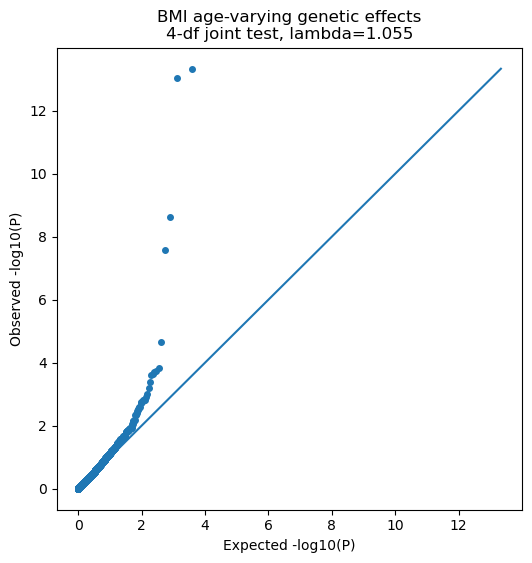

In [44]:
p_sorted = np.sort(p)

n = len(p_sorted)

expected = -np.log10(
    (np.arange(1, n + 1) - 0.5) / n
)

observed = -np.log10(p_sorted)

plt.figure(figsize=(6, 6))
plt.scatter(expected, observed, s=16)

mx = max(expected.max(), observed.max())
plt.plot([0, mx], [0, mx])

plt.xlabel("Expected -log10(P)")
plt.ylabel("Observed -log10(P)")
plt.title(
    f"BMI age-varying genetic effects\n"
    f"4-df joint test, lambda={lambda_gc_4df:.3f}"
)
plt.show()

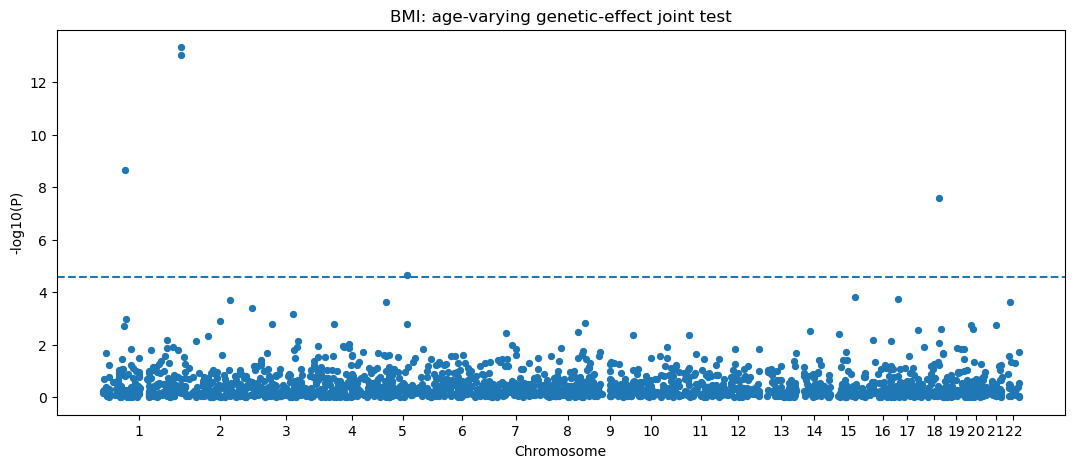

In [45]:
plot_df = bmi_joint.copy()

plot_df["CHR"] = pd.to_numeric(
    plot_df["#CHROM"],
    errors="coerce"
)

plot_df["POS"] = pd.to_numeric(
    plot_df["POS"],
    errors="coerce"
)

plot_df = (
    plot_df
    .sort_values(["CHR", "POS"])
    .reset_index(drop=True)
)

# cumulative genomic positions
offset = 0
ticks = []
ticklabels = []

plot_df["BPcum"] = np.nan

for chrom in range(1, 23):

    idx = plot_df["CHR"] == chrom

    if not idx.any():
        continue

    pos = plot_df.loc[idx, "POS"]

    plot_df.loc[idx, "BPcum"] = pos + offset

    ticks.append(
        plot_df.loc[idx, "BPcum"].median()
    )
    ticklabels.append(str(chrom))

    offset = plot_df.loc[idx, "BPcum"].max() + 5e6

plot_df["mlog10p"] = -np.log10(plot_df["P"])

plt.figure(figsize=(13, 5))

plt.scatter(
    plot_df["BPcum"],
    plot_df["mlog10p"],
    s=18
)

plt.axhline(
    -np.log10(0.05 / len(plot_df)),
    linestyle="--"
)

plt.xticks(ticks, ticklabels)
plt.xlabel("Chromosome")
plt.ylabel("-log10(P)")
plt.title("BMI: age-varying genetic-effect joint test")
plt.show()

In [46]:
manifest = pd.read_csv(
    FINAL / "variant_manifest_strict_biallelic.tsv",
    sep="\t",
    dtype=str
)

print(manifest.columns.tolist())

['chrom', 'start0', 'end0', 'rsid', 'POS', '#CHROM', 'ID', 'REF', 'ALT', 'effect_allele', 'other_allele', 'allele_definition']


In [47]:
bmi_joint_named = bmi_joint.merge(
    manifest[
        ["ID", "rsid", "REF", "ALT"]
    ].drop_duplicates("ID"),
    on="ID",
    how="left"
)

display(
    bmi_joint_named[
        [
            "#CHROM",
            "POS",
            "rsid",
            "ID",
            "A1",
            "A1_FREQ",
            "T_OR_F_STAT",
            "P",
            "FDR",
            "bonferroni"
        ]
    ].head(20)
)

,#CHROM,POS,rsid,ID,A1,A1_FREQ,T_OR_F_STAT,P,FDR,bonferroni
0,2,628504,rs6744646,chr2:628504:A,A,0.173241,17.12920,4.687630e-14,8.678427e-11,True
1,2,417167,rs62106258,chr2:417167:T,C,0.045824,16.78620,9.125580e-14,8.678427e-11,True
2,1,74539554,rs7553158,chr1:74539554:G,G,0.435741,11.53630,2.302010e-09,1.459474e-06,True
3,18,60181418,rs66922415,chr18:60181418:A,G,0.236152,10.27050,2.588930e-08,1.231036e-05,True
4,5,88387060,rs7442885,chr5:88387060:C,G,0.228777,6.68093,2.262040e-05,8.604800e-03,True
5,15,75148328,rs28818910,chr15:75148328:C,T,0.453903,5.66696,1.475810e-04,4.635726e-02,False
6,17,16040596,rs1075901,chr17:16040596:T,T,0.428312,5.56304,1.786090e-04,4.635726e-02,False
7,2,160249365,rs10803762,chr2:160249365:G,G,0.325322,5.51189,1.961790e-04,4.635726e-02,False
8,22,21946306,rs1530229,chr22:21946306:A,G,0.191976,5.41463,2.344450e-04,4.635726e-02,False
9,5,20190711,rs182281906,chr5:20190711:C,T,0.006726,5.39341,2.437290e-04,4.635726e-02,False


In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2

FIG_DIR = B1 / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def make_b1_plots(joint_df, trait):

    df = joint_df.copy()
    df = df.loc[df["P"].notna()].copy()

    # -----------------------
    # QQ plot
    # -----------------------
    p = df["P"].to_numpy()
    p_sorted = np.sort(p)

    n = len(p_sorted)

    expected = -np.log10(
        (np.arange(1, n + 1) - 0.5) / n
    )

    observed = -np.log10(p_sorted)

    # 4-df lambda
    chisq4 = chi2.isf(p, df=4)

    lambda_gc_4df = (
        np.median(chisq4)
        / chi2.ppf(0.5, df=4)
    )

    fig = plt.figure(figsize=(6, 6))

    plt.scatter(
        expected,
        observed,
        s=16
    )

    mx = max(
        expected.max(),
        observed.max()
    )

    plt.plot(
        [0, mx],
        [0, mx]
    )

    plt.xlabel("Expected -log10(P)")
    plt.ylabel("Observed -log10(P)")

    plt.title(
        f"{trait}: age-varying genetic effects\n"
        f"4-df joint test, lambda={lambda_gc_4df:.3f}"
    )

    plt.tight_layout()

    fig.savefig(
        FIG_DIR / f"{trait}_QQ.png",
        dpi=300,
        bbox_inches="tight"
    )

    fig.savefig(
        FIG_DIR / f"{trait}_QQ.pdf",
        bbox_inches="tight"
    )

    plt.close(fig)

    # -----------------------
    # Manhattan-like plot
    # -----------------------

    df["CHR"] = pd.to_numeric(
        df["#CHROM"],
        errors="coerce"
    )

    df["POS"] = pd.to_numeric(
        df["POS"],
        errors="coerce"
    )

    df = (
        df
        .sort_values(["CHR", "POS"])
        .reset_index(drop=True)
    )

    df["BPcum"] = np.nan

    offset = 0
    ticks = []
    ticklabels = []

    for chrom in range(1, 23):

        idx = df["CHR"] == chrom

        if not idx.any():
            continue

        pos = df.loc[idx, "POS"]

        df.loc[idx, "BPcum"] = (
            pos + offset
        )

        ticks.append(
            df.loc[idx, "BPcum"].median()
        )

        ticklabels.append(str(chrom))

        offset = (
            df.loc[idx, "BPcum"].max()
            + 5e6
        )

    df["mlog10p"] = -np.log10(
        df["P"]
    )

    fig = plt.figure(
        figsize=(13, 5)
    )

    plt.scatter(
        df["BPcum"],
        df["mlog10p"],
        s=18
    )

    # Bonferroni
    plt.axhline(
        -np.log10(
            0.05 / len(df)
        ),
        linestyle="--"
    )

    plt.xticks(
        ticks,
        ticklabels
    )

    plt.xlabel("Chromosome")
    plt.ylabel("-log10(P)")
    plt.title(
        f"{trait}: age-varying genetic-effect joint test"
    )

    plt.tight_layout()

    fig.savefig(
        FIG_DIR / f"{trait}_Manhattan.png",
        dpi=300,
        bbox_inches="tight"
    )

    fig.savefig(
        FIG_DIR / f"{trait}_Manhattan.pdf",
        bbox_inches="tight"
    )

    plt.close(fig)

    return lambda_gc_4df

In [49]:
bmi_lambda = make_b1_plots(
    bmi_joint,
    "BMI"
)

print("BMI lambda =", bmi_lambda)
print("Saved to:", FIG_DIR)

BMI lambda = 1.054720520221222
Saved to: /home/dataproc/workspace/agemr-data/final_cohort_v1/B1_age_varying/figures


In [50]:
from statsmodels.stats.multitest import multipletests
import subprocess


def run_b1_trait(
    trait,
    covar_df,
):

    print("\n" + "=" * 60)
    print("RUNNING:", trait)
    print("=" * 60)

    trait_results = (
        B1 / f"{trait}_results"
    )

    trait_results.mkdir(
        parents=True,
        exist_ok=True
    )

    # -----------------------
    # PLINK parameter indices
    # -----------------------

    K = 4
    q = covar_df.shape[1] - 1

    assert (
        covar_df.columns[1:5].tolist()
        == ["B1", "B2", "B3", "B4"]
    )

    parameters = (
        f"1-{1 + q + K}"
    )

    tests = (
        f"{2 + q}-{1 + q + K}"
    )

    print(
        "q =", q,
        "parameters =", parameters,
        "tests =", tests
    )

    # -----------------------
    # run chr1-22
    # -----------------------

    run_summary = []

    for c in range(1, 23):

        chrom = f"chr{c}"

        print(
            f"{trait}: running {chrom}"
        )

        # Same genotype panel for all traits
        pfile = (
            GENO / f"BMI_{chrom}"
        )

        out = (
            trait_results
            / f"{trait}_{chrom}"
        )

        cmd = [
            PLINK2,

            "--pfile", str(pfile),

            "--pheno",
            str(B1 / f"{trait}.pheno.tsv"),

            "--pheno-name",
            trait,

            "--covar",
            str(B1 / f"{trait}.covar.tsv"),

            "--glm",
            "interaction",
            "hide-covar",

            "--parameters",
            parameters,

            "--tests",
            tests,

            "--out",
            str(out)
        ]

        res = subprocess.run(
            cmd,
            capture_output=True,
            text=True
        )

        run_summary.append({
            "trait": trait,
            "chrom": chrom,
            "return_code":
                res.returncode
        })

        if res.returncode != 0:

            print(res.stdout)
            print(res.stderr)

            raise RuntimeError(
                f"{trait} failed on {chrom}"
            )

    print(
        f"{trait}: all chromosomes finished."
    )

    # -----------------------
    # merge results
    # -----------------------

    all_joint = []

    for c in range(1, 23):

        chrom = f"chr{c}"

        f = (
            trait_results
            / f"{trait}_{chrom}.{trait}.glm.linear"
        )

        assert f.exists(), f

        z = pd.read_csv(
            f,
            sep="\t"
        )

        j = z.loc[
            z["TEST"] == "USER_4DF"
        ].copy()

        all_joint.append(j)

    joint = pd.concat(
        all_joint,
        ignore_index=True
    )

    assert (
        joint["P"].isna().sum()
        == 0
    )

    # -----------------------
    # multiple testing
    # -----------------------

    n_snp = len(joint)

    joint["bonferroni"] = (
        joint["P"]
        < 0.05 / n_snp
    )

    reject, qval, _, _ = (
        multipletests(
            joint["P"],
            method="fdr_bh"
        )
    )

    joint["FDR"] = qval
    joint["FDR_005"] = reject

    joint = (
        joint
        .sort_values("P")
        .reset_index(drop=True)
    )

    # -----------------------
    # save result table
    # -----------------------

    joint.to_csv(
        B1
        / f"{trait}_age_varying_joint_tests.tsv",
        sep="\t",
        index=False
    )

    # -----------------------
    # plots
    # -----------------------

    lambda_gc = make_b1_plots(
        joint,
        trait
    )

    # -----------------------
    # summary
    # -----------------------

    summary = {
        "Trait": trait,
        "N_SNP": n_snp,
        "P_lt_0.05":
            int(
                (joint["P"] < 0.05).sum()
            ),
        "FDR_lt_0.05":
            int(
                joint["FDR_005"].sum()
            ),
        "Bonferroni":
            int(
                joint["bonferroni"].sum()
            ),
        "Bonf_threshold":
            0.05 / n_snp,
        "lambda_4df":
            lambda_gc,
        "median_OBS_CT":
            float(
                joint["OBS_CT"].median()
            )
    }

    print("\n", summary)

    return joint, summary

In [51]:
sbp_joint, sbp_summary = run_b1_trait(
    "SBP",
    sbp_covar
)

dbp_joint, dbp_summary = run_b1_trait(
    "DBP",
    dbp_covar
)


RUNNING: SBP
q = 19 parameters = 1-24 tests = 21-24
SBP: running chr1
SBP: running chr2
SBP: running chr3
SBP: running chr4
SBP: running chr5
SBP: running chr6
SBP: running chr7
SBP: running chr8
SBP: running chr9
SBP: running chr10
SBP: running chr11
SBP: running chr12
SBP: running chr13
SBP: running chr14
SBP: running chr15
SBP: running chr16
SBP: running chr17
SBP: running chr18
SBP: running chr19
SBP: running chr20
SBP: running chr21
SBP: running chr22
SBP: all chromosomes finished.

 {'Trait': 'SBP', 'N_SNP': 1902, 'P_lt_0.05': 122, 'FDR_lt_0.05': 0, 'Bonferroni': 0, 'Bonf_threshold': 2.6288117770767615e-05, 'lambda_4df': 1.0208989348556707, 'median_OBS_CT': 217814.0}

RUNNING: DBP
q = 19 parameters = 1-24 tests = 21-24
DBP: running chr1
DBP: running chr2
DBP: running chr3
DBP: running chr4
DBP: running chr5
DBP: running chr6
DBP: running chr7
DBP: running chr8
DBP: running chr9
DBP: running chr10
DBP: running chr11
DBP: running chr12
DBP: running chr13
DBP: running chr14
DBP: ru

In [52]:
bmi_summary = {
    "Trait": "BMI",
    "N_SNP": len(bmi_joint),
    "P_lt_0.05":
        int(
            (bmi_joint["P"] < 0.05).sum()
        ),
    "FDR_lt_0.05":
        int(
            bmi_joint["FDR_005"].sum()
        ),
    "Bonferroni":
        int(
            bmi_joint["bonferroni"].sum()
        ),
    "Bonf_threshold":
        0.05 / len(bmi_joint),
    "lambda_4df":
        bmi_lambda,
    "median_OBS_CT":
        float(
            bmi_joint["OBS_CT"].median()
        )
}

In [53]:
b1_summary = pd.DataFrame([
    bmi_summary,
    sbp_summary,
    dbp_summary
])

display(b1_summary)

b1_summary.to_csv(
    B1 / "B1_trait_summary.tsv",
    sep="\t",
    index=False
)

,Trait,N_SNP,P_lt_0.05,FDR_lt_0.05,Bonferroni,Bonf_threshold,lambda_4df,median_OBS_CT
0,BMI,1902,132,10,5,0.000026,1.054721,247450.0
1,SBP,1902,122,0,0,0.000026,1.020899,217814.0
2,DBP,1902,123,0,0,0.000026,1.039917,217814.0


In [54]:
def run_main_effect_gwas(trait):

    outdir = B1 / f"{trait}_main_effect"
    outdir.mkdir(parents=True, exist_ok=True)

    all_add = []

    for c in range(1, 23):

        chrom = f"chr{c}"

        pfile = GENO / f"BMI_{chrom}"
        out = outdir / f"{trait}_{chrom}"

        cmd = [
            PLINK2,
            "--pfile", str(pfile),

            "--pheno",
            str(B1 / f"{trait}.pheno.tsv"),

            "--pheno-name",
            trait,

            "--covar",
            str(B1 / f"{trait}.covar.tsv"),

            "--glm", "hide-covar",

            "--out", str(out)
        ]

        res = subprocess.run(
            cmd,
            capture_output=True,
            text=True
        )

        if res.returncode != 0:
            print(res.stdout)
            print(res.stderr)
            raise RuntimeError(
                f"{trait} failed on {chrom}"
            )

        f = (
            outdir /
            f"{trait}_{chrom}.{trait}.glm.linear"
        )

        z = pd.read_csv(
            f,
            sep="\t"
        )

        add = z.loc[
            z["TEST"] == "ADD"
        ].copy()

        all_add.append(add)

    main = pd.concat(
        all_add,
        ignore_index=True
    )

    main = main.rename(columns={
        "BETA": "BETA_main",
        "SE": "SE_main",
        "P": "P_main",
        "T_OR_F_STAT": "T_main"
    })

    main.to_csv(
        B1 / f"{trait}_pooled_main_effect.tsv",
        sep="\t",
        index=False
    )

    return main

In [ ]:
bmi_main = run_main_effect_gwas("BMI")
sbp_main = run_main_effect_gwas("SBP")
dbp_main = run_main_effect_gwas("DBP")

In [ ]:
bmi_compare = (
    bmi_joint[
        [
            "ID",
            "#CHROM",
            "POS",
            "P",
            "FDR",
            "bonferroni"
        ]
    ]
    .rename(
        columns={"P": "P_interaction"}
    )
    .merge(
        bmi_main[
            [
                "ID",
                "BETA_main",
                "SE_main",
                "P_main"
            ]
        ],
        on="ID",
        how="left"
    )
)

In [ ]:
bmi_compare["interaction_FDR"] = (
    bmi_compare["FDR"] < 0.05
)

bmi_compare["interaction_Bonf"] = (
    bmi_compare["bonferroni"]
)

bmi_compare["main_nominal"] = (
    bmi_compare["P_main"] < 0.05
)

bmi_compare["main_Bonf"] = (
    bmi_compare["P_main"]
    < 0.05 / len(bmi_compare)
)